# Machine Learning Model - Training & Testing (Dynamic Dataset Control)
## Network Intrusion Detection System



### Model:

. XGBoost


In [10]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.


In [1]:
# ========================================
# MERGE MULTIPLE LARGE CSVs INTO ONE FILE
# ========================================

import pandas as pd
import os

# Collect all CSV files in current directory
csv_files = [f for f in os.listdir() if f.endswith(".csv")]
print("📂 Found CSV files:", csv_files)

# Output path
os.makedirs("archive", exist_ok=True)
output_file = "archive/full_df_binary_labels.csv"

# Merge in chunks to avoid memory issues
first = True
for file in csv_files:
    print(f"⏳ Processing {file}...")
    for chunk in pd.read_csv(file, chunksize=100000, low_memory=False):
        # Normalize label column name if present
        for col in chunk.columns:
            if col.lower() in ["label", "labels", "attack", "class"]:
                chunk.rename(columns={col: "label"}, inplace=True)
                break

        # Append chunk to output file
        chunk.to_csv(output_file, mode="a", index=False, header=first)
        first = False

print(f"\n💾 Saved merged dataset to: {output_file}")

# ========================================
# QUICK SANITY CHECK
# ========================================
df_check = pd.read_csv(output_file, nrows=5)
print("\n✅ First few rows of merged dataset:")
print(df_check.head())
print("\n✅ Columns:", list(df_check.columns))



📂 Found CSV files: ['03-02-2018.csv', '03-01-2018.csv', '02-28-2018.csv', '02-23-2018.csv', '02-22-2018.csv', '02-21-2018.csv', '02-20-2018.csv', '02-16-2018.csv', '02-15-2018.csv', '02-14-2018.csv']
⏳ Processing 03-02-2018.csv...
⏳ Processing 03-01-2018.csv...
⏳ Processing 02-28-2018.csv...
⏳ Processing 02-23-2018.csv...
⏳ Processing 02-22-2018.csv...
⏳ Processing 02-21-2018.csv...
⏳ Processing 02-20-2018.csv...
⏳ Processing 02-16-2018.csv...
⏳ Processing 02-15-2018.csv...
⏳ Processing 02-14-2018.csv...

💾 Saved merged dataset to: archive/full_df_binary_labels.csv

✅ First few rows of merged dataset:
   Dst Port  Protocol            Timestamp  Flow Duration  Tot Fwd Pkts  \
0       443         6  02/03/2018 08:47:38         141385             9   
1     49684         6  02/03/2018 08:47:38            281             2   
2       443         6  02/03/2018 08:47:40         279824            11   
3       443         6  02/03/2018 08:47:40            132             2   
4       443     

In [1]:
import pandas as pd
import numpy as np
import time
import pickle
import warnings
warnings.filterwarnings('ignore')
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# ML Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
import numpy as np

INPUT_FILE = "archive/full_df_binary_labels.csv"
CHUNK_SIZE = 100000

print("⏳ Reading dataset in chunks...")

chunks = []

for chunk in pd.read_csv(INPUT_FILE, chunksize=CHUNK_SIZE, engine="python", on_bad_lines="skip"):
    # Binary label: 0 = Benign, 1 = Attack
    chunk["Label_Binary"] = chunk["label"].apply(
        lambda x: 0 if str(x).lower() == "benign" else 1
    )
    chunks.append(chunk)

df_full = pd.concat(chunks, ignore_index=True)
del chunks

print(f"✅ Dataset loaded: {df_full.shape}")


⏳ Reading dataset in chunks...
✅ Dataset loaded: (8284254, 81)


In [4]:
pip install xgboost


  Using cached xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl.metadata (2.1 kB)
Using cached xgboost-3.2.0-py3-none-manylinux_2_28_x86_64.whl (131.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Features + labels
X_full = df_full.drop(["label", "Label_Binary"], axis=1)
y_full = df_full["Label_Binary"]

# Convert everything to numeric
X_full = X_full.apply(pd.to_numeric, errors="coerce")

# Handle bad values
X_full = X_full.replace([np.inf, -np.inf], np.nan)
X_full = X_full.dropna(axis=1, how="all")
X_full = X_full.fillna(X_full.median())

# VERY IMPORTANT: reduce memory
X_full = X_full.astype("float32")

print(f"✅ Features: {X_full.shape}")
print(f"✅ Labels: {y_full.shape}")


✅ Features: (8284254, 78)
✅ Labels: (8284254,)


In [5]:

# =================================================
# new training one (70 -15-15 ) 3-way split
# =================================================

from sklearn.model_selection import train_test_split

# 70% train, 15% val, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X_full,
    y_full,
    test_size=0.30,
    random_state=42,
    stratify=y_full
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

Train: (5798977, 78)
Val  : (1242638, 78)
Test : (1242639, 78)


In [6]:
# =============================
# old training one (80 -20)
# =============================

from xgboost import XGBClassifier
import pickle

MODEL_PATH = "xgb_full_cpu.pkl"

xgb_model = XGBClassifier(
    tree_method="hist",
    device="cpu",
    max_depth=6,
    n_estimators=300,
    learning_rate=0.05,
    subsample=0.7,
    colsample_bytree=0.7,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)

print("⏳ Training XGBoost on FULL dataset (CPU)...")

xgb_model.fit(X_train, y_train)

print("✅ Training complete")

with open(MODEL_PATH, "wb") as f:
    pickle.dump(xgb_model, f)

print(f"💾 Model saved to {MODEL_PATH}")


⏳ Training XGBoost on FULL dataset (CPU)...
✅ Training complete
💾 Model saved to xgb_full_cpu.pkl


In [6]:


# =============================
# new training one (70 -15-15)
# =============================



from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    early_stopping_rounds=50,
    verbose=True
)

[0]	validation_0-logloss:0.53331
[1]	validation_0-logloss:0.49652
[2]	validation_0-logloss:0.46443
[3]	validation_0-logloss:0.43628
[4]	validation_0-logloss:0.41050
[5]	validation_0-logloss:0.38702
[6]	validation_0-logloss:0.36565
[7]	validation_0-logloss:0.34616
[8]	validation_0-logloss:0.32830
[9]	validation_0-logloss:0.31196
[10]	validation_0-logloss:0.29701
[11]	validation_0-logloss:0.28308
[12]	validation_0-logloss:0.27031
[13]	validation_0-logloss:0.25829
[14]	validation_0-logloss:0.24737
[15]	validation_0-logloss:0.23684
[16]	validation_0-logloss:0.22716
[17]	validation_0-logloss:0.21814
[18]	validation_0-logloss:0.20963
[19]	validation_0-logloss:0.20179
[20]	validation_0-logloss:0.19451
[21]	validation_0-logloss:0.18764
[22]	validation_0-logloss:0.18106
[23]	validation_0-logloss:0.17486
[24]	validation_0-logloss:0.16921
[25]	validation_0-logloss:0.16392
[26]	validation_0-logloss:0.15870
[27]	validation_0-logloss:0.15376
[28]	validation_0-logloss:0.14911
[29]	validation_0-loglos

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [7]:
# =============================
# final test evaluation
# =============================



from sklearn.metrics import classification_report

y_test_pred = model.predict(X_test)
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9750    0.9993    0.9870    916823
           1     0.9980    0.9279    0.9616    325816

    accuracy                         0.9806   1242639
   macro avg     0.9865    0.9636    0.9743   1242639
weighted avg     0.9810    0.9806    0.9804   1242639



In [8]:

# =============================
# proper IDS metrics
# =============================


from sklearn.metrics import roc_auc_score, average_precision_score

y_test_proba = model.predict_proba(X_test)[:, 1]

print("ROC-AUC :", roc_auc_score(y_test, y_test_proba))
print("PR-AUC  :", average_precision_score(y_test, y_test_proba))

ROC-AUC : 0.9927209579954732
PR-AUC  : 0.9867603629398002


<Figure size 1000x600 with 0 Axes>

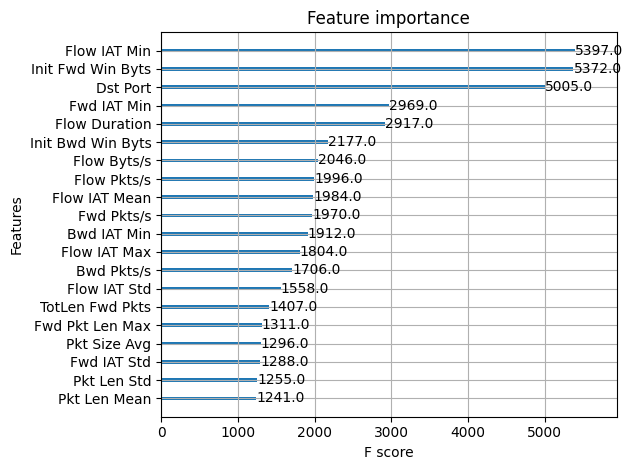

In [9]:
# =============================
# feature importance
# =============================

import matplotlib.pyplot as plt
from xgboost import plot_importance

plt.figure(figsize=(10,6))
plot_importance(model, max_num_features=20)
plt.tight_layout()
plt.show()

In [15]:


# =================================================
# false positives / false negatives analysis
# =================================================


import numpy as np

y_true = np.asarray(y_test)
y_pred = np.asarray(y_test_pred)

fp = ((y_true == 0) & (y_pred == 1)).sum()
fn = ((y_true == 1) & (y_pred == 0)).sum()

print("False positives:", fp)
print("False negatives:", fn)

print("FP rate:", fp / (y_true == 0).sum())
print("FN rate:", fn / (y_true == 1).sum())

False positives: 610
False negatives: 23504
FP rate: 0.0006653410745585571
FN rate: 0.07213887592997274


## 🔍 Why we go beyond ROC-AUC / PR-AUC and tune the decision threshold

At this stage, the XGBoost model already achieves very high global performance
(ROC-AUC and PR-AUC close to 1).  
However, in a real Intrusion Detection System (IDS), overall metrics are not sufficient.

What really matters in practice is:

- ❗ False Negatives (FN): attacks that are not detected
- ⚠️ False Positives (FP): normal traffic wrongly classified as attacks

By default, the classifier uses a fixed probability threshold of 0.5 to decide
whether a traffic flow is an attack or not.  
This default threshold is not optimized for IDS requirements.

In security monitoring, missing an attack is usually more critical than generating
a false alert.  
Therefore, instead of changing the model, the next step is to adjust the decision
threshold in order to prioritize a higher attack detection rate (higher recall),
even if this increases the number of false positives.

The following cells compute the Precision–Recall curve and select a decision
threshold that better fits real IDS constraints.

In [11]:


# =======================================
# better IDS threshold (recall-oriented)
# =========================================




from sklearn.metrics import precision_recall_curve
import numpy as np

# Probabilities for the attack class
y_scores = model.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

# We want to favor attack detection (high recall)
target_recall = 0.95

idx = np.where(recalls >= target_recall)[0][-1]

best_threshold = thresholds[idx]

print("Chosen threshold:", best_threshold)
print("Precision at this threshold:", precisions[idx])
print("Recall at this threshold:", recalls[idx])

Chosen threshold: 0.17679815
Precision at this threshold: 0.9488172201224316
Recall at this threshold: 0.9500024553735851


In [12]:

#================================================
# New predictions using IDS-oriented threshold
#================================================
y_pred_ids = (y_scores >= best_threshold).astype(int)

y_true = np.asarray(y_test)

fp = ((y_true == 0) & (y_pred_ids == 1)).sum()
fn = ((y_true == 1) & (y_pred_ids == 0)).sum()

print("False positives:", fp)
print("False negatives:", fn)

print("FP rate:", fp / (y_true == 0).sum())
print("FN rate:", fn / (y_true == 1).sum())

False positives: 16697
False negatives: 16290
FP rate: 0.01821180315066267
FN rate: 0.04999754462641491


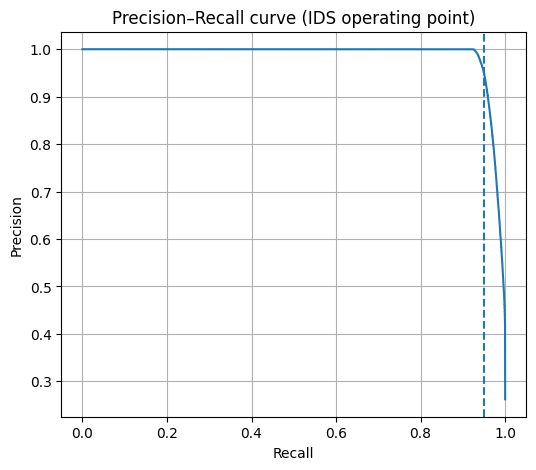

In [13]:
#====================================================
#   Precision–Recall curve 
#====================================================








from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.plot(recalls, precisions)
plt.axvline(0.95, linestyle="--")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curve (IDS operating point)")
plt.grid(True)
plt.show()

##  IDS decision threshold tuning – interpretation of the results

The default classification threshold (0.5) was replaced by a threshold selected from the
Precision–Recall curve in order to better match real Intrusion Detection System (IDS)
requirements.

Using the new threshold:

- Chosen threshold: 0.1768  
- Precision: 94.88%  
- Recall (attack detection rate): 95.00%

Comparison with the default configuration:

- False negative rate decreased from about 7.2% to 5.0  
- The number of missed attacks was significantly reduced  
- The false positive rate increased from about 0.07% to 1.82%

This behavior is expected and acceptable in an IDS context.
Missing attacks (false negatives) is more critical than generating additional alerts
(false positives).

Therefore, the system is intentionally configured to favor higher recall, leading to a
more security-oriented operating point.
This adjustment improves the practical usefulness of the model for intrusion detection
without changing the trained classifier itself.

In [7]:


# =============================
# optimisation(first try)
# =============================



from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

print("🚀 Training Optimized Model (Manual Safe Mode)...")

optimized_model = XGBClassifier(
    tree_method="hist",
    device="cpu",
    max_depth=5,          # slightly lower depth
    n_estimators=250,     # slightly fewer trees
    learning_rate=0.03,   # smaller learning rate
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    n_jobs=2,             # limited CPU
    random_state=42
)

optimized_model.fit(X_train, y_train)

print("✅ Optimized model trained successfully")


🚀 Training Optimized Model (Manual Safe Mode)...
✅ Optimized model trained successfully


In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# ========================================
# MODEL EVALUATION(for first opt try) 
# ========================================

y_pred = xgb_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\n🎯 Accuracy:", accuracy)

# Classification Report
print("\n📊 Classification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix (store it for plotting)
cm = confusion_matrix(y_test, y_pred)

print("\n🧩 Confusion Matrix:\n")
print(cm)



🎯 Accuracy: 0.9803887012169471

📊 Classification Report:

              precision    recall  f1-score   support

           0       0.97      1.00      0.99   1222430
           1       1.00      0.93      0.96    434421

    accuracy                           0.98   1656851
   macro avg       0.99      0.96      0.97   1656851
weighted avg       0.98      0.98      0.98   1656851


🧩 Confusion Matrix:

[[1221735     695]
 [  31798  402623]]


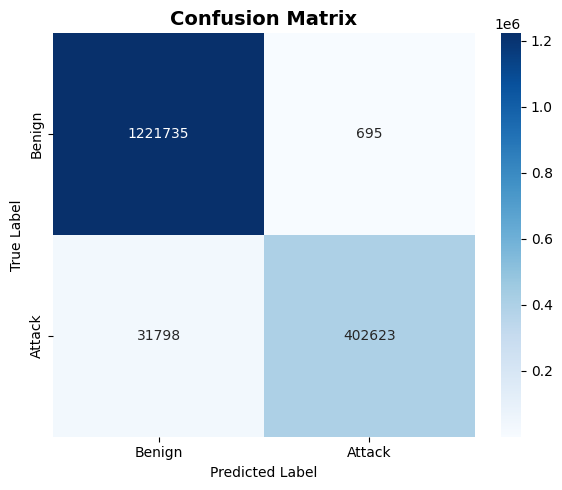

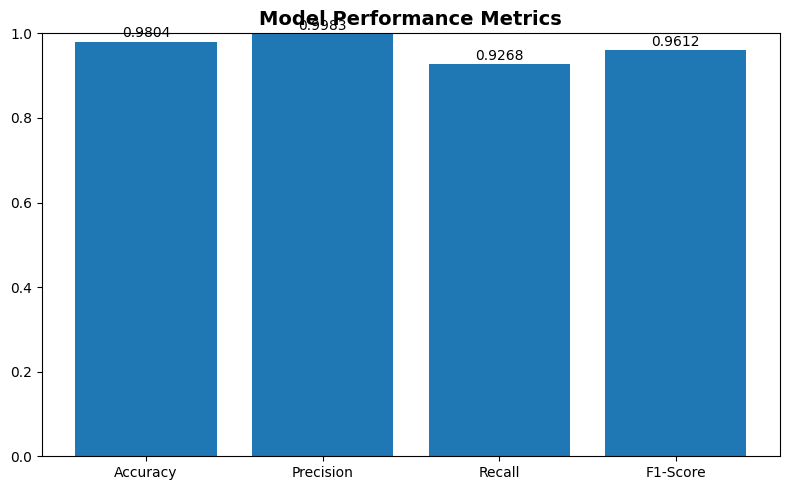

In [14]:

# ========================================
# CONFUSION MATRIX VISUALIZATION  (old one)
# ========================================

import matplotlib.pyplot as plt
import seaborn as sns

# ========================================
# CONFUSION MATRIX VISUALIZATION
# ========================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)

plt.title("Confusion Matrix", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


# ========================================
# METRICS BAR CHART
# ========================================

from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, values)

plt.title("Model Performance Metrics", fontsize=14, fontweight='bold')
plt.ylim(0, 1)

for i in range(len(values)):
    plt.text(i, values[i] + 0.01, f"{values[i]:.4f}", ha='center')

plt.tight_layout()
plt.show()


In [8]:
import xgboost
print(xgboost.__version__)


3.2.0


In [9]:
!pip install xgboost==2.0.3


  Using cached xgboost-2.0.3-py3-none-manylinux2014_x86_64.whl.metadata (2.0 kB)
Using cached xgboost-2.0.3-py3-none-manylinux2014_x86_64.whl (297.1 MB)
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.2.0
    Uninstalling xgboost-3.2.0:
      Successfully uninstalled xgboost-3.2.0


In [10]:
from xgboost import XGBClassifier
XGBClassifier(tree_method="gpu_hist")


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [14]:


import time  
from sklearn.metrics import confusion_matrix


Baseline Accuracy: 0.9803887012169471
Optimized Accuracy: 0.9801394331777571


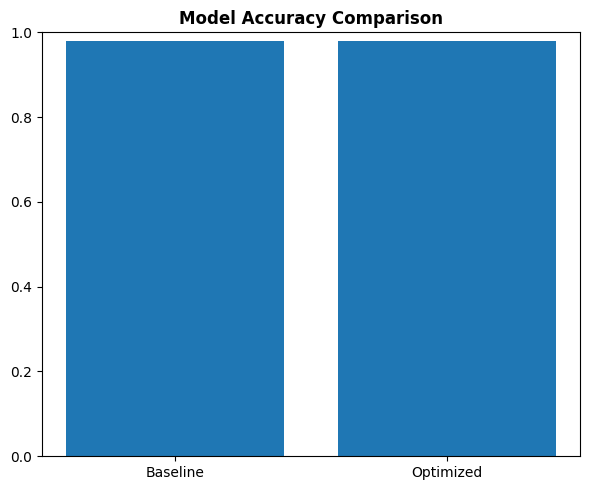

In [8]:


# ========================================
# CONFUSION MATRIX VISUALIZATION(old one)
# ========================================




import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Baseline
y_pred_base = xgb_model.predict(X_test)
acc_base = accuracy_score(y_test, y_pred_base)

# Optimized
y_pred_opt = optimized_model.predict(X_test)
acc_opt = accuracy_score(y_test, y_pred_opt)

print("Baseline Accuracy:", acc_base)
print("Optimized Accuracy:", acc_opt)

plt.figure(figsize=(6,5))
plt.bar(["Baseline", "Optimized"], [acc_base, acc_opt])
plt.title("Model Accuracy Comparison", fontweight="bold")
plt.ylim(0,1)
plt.tight_layout()
plt.show()

In [9]:
# ========================================
#early stopping try
# ========================================


from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

print("🚀 Training with Early Stopping...")

early_model = XGBClassifier(
    tree_method="hist",
    device="cpu",
    max_depth=6,
    n_estimators=1000,          
    learning_rate=0.05,
    subsample=0.7,
    colsample_bytree=0.7,
    eval_metric="logloss",
    n_jobs=2,
    random_state=42
)

early_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

y_pred_early = early_model.predict(X_test)
acc_early = accuracy_score(y_test, y_pred_early)

print("Early Stopping Accuracy:", acc_early)

🚀 Training with Early Stopping...
Early Stopping Accuracy: 0.9805751995804088


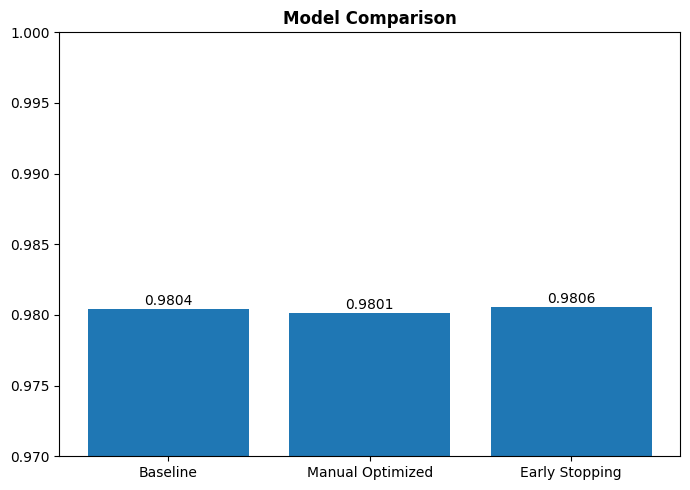

In [10]:
# ========================================
#first opt try
# ========================================
import matplotlib.pyplot as plt

models = ["Baseline", "Manual Optimized", "Early Stopping"]
accuracies = [acc_base, acc_opt, acc_early]

plt.figure(figsize=(7,5))
plt.bar(models, accuracies)

plt.title("Model Comparison", fontweight="bold")
plt.ylim(0.97, 1)

for i in range(len(accuracies)):
    plt.text(i, accuracies[i] + 0.0003, f"{accuracies[i]:.4f}", ha='center')

plt.tight_layout()
plt.show()